# Cuando una palabra no estaba en el entrenamiento: fastText

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un sistema recibe palabras que su modelo nunca vio (erratas, neologismos, palabras locales). |
| **Producto** | Dos funciones que reconstruyen vectores y un informe de cobertura de tres palabras, con tu decisión de uso. |
| **Recursos** | Secciones 1 y 2: poca memoria. Secciones 3 a 5: unos 7 GB (`wiki.es.bin`) y más de un minuto de carga. |

Un corrector, un buscador o un clasificador reciben palabras que su modelo nunca vio. Word2Vec no tiene vector para ellas. fastText siempre devuelve uno.

**¿Cuándo ese vector sirve y cuándo solo parece una respuesta?**

> **Cómo se trabaja.** Primero explorás un tema con el código ya escrito y las notas **Para mirar**. Al final de cada bloque hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import gc
import sys
import time
import zlib
import importlib.metadata

import numpy as np
import pandas as pd
from IPython.display import display

from gensim.models import FastText, KeyedVectors, Word2Vec
from gensim.models.fasttext import compute_ngrams, ft_ngram_hashes

import utils

# La semilla fija el azar del entrenamiento de los modelos chicos.
SEMILLA = 42
pd.set_option("display.max_colwidth", 100)

print("Python:", sys.version.split()[0])
for paquete in ["gensim", "numpy", "pandas"]:
    print(f"{paquete}: {importlib.metadata.version(paquete)}")
print("Semilla:", SEMILLA)

Python: 3.12.13
gensim: 4.4.0
numpy: 2.5.4
pandas: 3.0.6
Semilla: 42


## 1. Leer por pedazos

fastText corta cada palabra en **n-gramas de caracteres**, con `<` y `>` marcando el inicio y el final. Cambiá `MAXIMO_DE_LETRAS` a 4 y a 8 y mirá cuántos n-gramas quedan.

In [2]:
MINIMO_DE_LETRAS = 3
MAXIMO_DE_LETRAS = 6

palabra = "amarillo"
palabra_con_marcas = "<" + palabra + ">"

# Recorremos la palabra con ventanas de cada tamano, de izquierda a derecha.
n_gramas = []
for tamano in range(MINIMO_DE_LETRAS, MAXIMO_DE_LETRAS + 1):
    for inicio in range(len(palabra_con_marcas) - tamano + 1):
        n_gramas.append(palabra_con_marcas[inicio:inicio + tamano])

# Control: nuestra lista es la misma que usa gensim.
esperados = compute_ngrams(palabra, MINIMO_DE_LETRAS, MAXIMO_DE_LETRAS)
assert n_gramas == esperados, "No coincide con la definicion de gensim."
print(f"'{palabra}' -> {len(n_gramas)} n-gramas")
print(n_gramas[:12], "...")

'amarillo' -> 26 n-gramas
['<am', 'ama', 'mar', 'ari', 'ril', 'ill', 'llo', 'lo>', '<ama', 'amar', 'mari', 'aril'] ...


> **Para mirar.** las marcas distinguen `<am` (al comienzo de la palabra) de `am` en el medio. La última línea confirma que la lista es la misma que usa gensim.

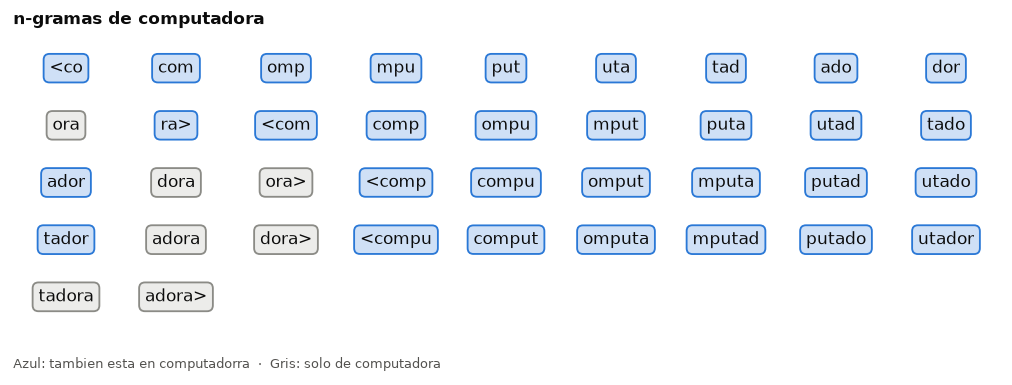

computadora: 38 n-gramas | computadorra: 42 | en comun: 31


In [3]:
de_computadora = compute_ngrams("computadora", 3, 6)
de_computadorra = compute_ngrams("computadorra", 3, 6)
en_comun = set(de_computadora) & set(de_computadorra)

clases = []
for n_grama in de_computadora:
    if n_grama in en_comun:
        clases.append("comparte")
    else:
        clases.append("propio")

utils.dibujar_fichas(
    de_computadora, clases,
    estilos={
        "comparte": (utils.AZUL, "Azul", "tambien esta en computadorra"),
        "propio": (utils.GRIS, "Gris", "solo de computadora"),
    },
    titulo="n-gramas de computadora",
    por_fila=9,
)
print(f"computadora: {len(de_computadora)} n-gramas | "
      f"computadorra: {len(de_computadorra)} | en comun: {len(en_comun)}")

> **Para mirar.** una errata comparte la mayoría de sus fragmentos con la palabra correcta, y por eso fastText puede acercarlas. Pero los n-gramas no saben de significado: también acercan palabras que solo se *escriben* parecido.

## 2. Dos modelos chicos, un solo cambio

Entrenamos Word2Vec y fastText con **los mismos textos** (137 fragmentos del curso) y los mismos parámetros: solo cambia el método. `cocinero` está en los textos; `cocinerazo` lo inventamos y no.

In [4]:
fragmentos = utils.cargar_fragmentos()

oraciones_para_entrenar = []
for texto in fragmentos["texto"]:
    oraciones_para_entrenar.append(utils.separar_palabras(texto))


def hash_estable(palabra: str) -> int:
    """Calcula un numero que depende solo de las letras de la palabra.

    Con workers=1 y este hash, el entrenamiento da igual en cada sesion.

    Args:
        palabra: La palabra a convertir.

    Returns:
        Un entero positivo.
    """
    return zlib.crc32(palabra.encode("utf-8"))


parametros = dict(
    vector_size=30, window=5, min_count=2, epochs=30,
    seed=SEMILLA, workers=1, hashfxn=hash_estable,
)
word2vec_chico = Word2Vec(sentences=oraciones_para_entrenar, **parametros).wv
fasttext_chico = FastText(
    sentences=oraciones_para_entrenar, min_n=3, max_n=6, **parametros
).wv

# Controles: cocinero esta en los textos, cocinerazo no.
texto_completo = " ".join(fragmentos["texto"]).lower()
assert "cocinero" in word2vec_chico.key_to_index, "Falta cocinero."
assert "cocinerazo" not in texto_completo, "No deberia estar cocinerazo."

filas = []
for palabra in ["cocinero", "cocinerazo"]:
    filas.append({
        "palabra": palabra,
        "Word2Vec: tiene vector": palabra in word2vec_chico,
        "fastText: vocabulario explicito":
            palabra in fasttext_chico.key_to_index,
        "fastText: 'in'": palabra in fasttext_chico,
    })
display(pd.DataFrame(filas).set_index("palabra"))

,Word2Vec: tiene vector,fastText: vocabulario explicito,fastText: 'in'
palabra,,,
cocinero,True,True,True
cocinerazo,False,False,True


> **Para mirar.** con los mismos datos, Word2Vec no puede con `cocinerazo` y fastText sí. Ojo con las dos columnas de fastText: `key_to_index` dice si la palabra estuvo en el entrenamiento; `in` casi siempre dice `True` (gensim lo responde sin mirar la palabra). **Cobertura no es calidad.**

¿De dónde sale el vector de `cocinerazo`? De sus n-gramas: cada uno tiene una fila en una tabla de `bucket` posiciones, y `ft_ngram_hashes` calcula cuáles.

In [5]:
palabra = "cocinerazo"
posiciones = ft_ngram_hashes(
    palabra, fasttext_chico.min_n, fasttext_chico.max_n, fasttext_chico.bucket
)
vectores_de_n_gramas = fasttext_chico.vectors_ngrams[posiciones]

promedio = np.mean(vectores_de_n_gramas, axis=0)
assert np.allclose(promedio, fasttext_chico[palabra]), "No coincide."
print(f"{palabra}: {len(posiciones)} n-gramas en una tabla de "
      f"{fasttext_chico.bucket:,} posiciones.")
print("El promedio coincide con el vector del modelo.")

# Para una palabra que si estuvo en el entrenamiento, se suma ademas
# su vector propio y se divide por la cantidad de sumandos.
palabra = "cocinero"
posiciones = ft_ngram_hashes(
    palabra, fasttext_chico.min_n, fasttext_chico.max_n, fasttext_chico.bucket
)
lugar = fasttext_chico.key_to_index[palabra]
suma = fasttext_chico.vectors_vocab[lugar]
suma = suma + fasttext_chico.vectors_ngrams[posiciones].sum(axis=0)
assert np.allclose(suma / (len(posiciones) + 1), fasttext_chico[palabra])
print(f"{palabra}: promedio de su vector propio y {len(posiciones)} n-gramas.")

cocinerazo: 34 n-gramas en una tabla de 2,000,000 posiciones.
El promedio coincide con el vector del modelo.
cocinero: promedio de su vector propio y 26 n-gramas.


> **Para mirar.** el vector de una palabra ausente es **el promedio de los vectores de sus n-gramas**; no usa ninguna información sobre qué significa. Para una palabra vista, el promedio incluye también su propio vector.

### Microlaboratorio 1 — Reconstruir vectores de palabras ausentes

**Tarea.** Escribir dos funciones y probarlas con palabras inventadas.  
**Producto.** `n_gramas_de` y `vector_por_n_gramas`, ambas comprobadas.  
**Antes de empezar.** Secciones 1 y 2.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `marcada` | la palabra entre marcas | concatenación de `"<"`, `palabra` y `">"` |
| (2) `fragmento` | un n-grama | una porción de `marcada`: `marcada[a:b]`, con `a = inicio` y `b = inicio + tamano` |
| (3) `posiciones` | dónde está cada n-grama en la tabla | `ft_ngram_hashes` con 4 argumentos, en este orden: `palabra`, `vectores.min_n`, `vectores.max_n`, `vectores.bucket` |
| (4) `vector` | un único vector | `np.mean` de `vectores.vectors_ngrams[posiciones]`, con `axis=0` |

**Comprobación.** las pruebas usan `compute_ngrams` y el modelo chico de la sección 2; dicen `Correcto.` o te dan una pista.

> **Ayuda 1.** Mirá el bucle de la sección 1: es la misma lógica.  
> **Ayuda 2.** Las líneas (3) y (4) repiten lo que hicimos con `cocinerazo`, pero dentro de una función que recibe el modelo como argumento.

In [6]:
def n_gramas_de(palabra: str, minimo: int, maximo: int) -> list:
    """Lista los n-gramas de caracteres de una palabra.

    Args:
        palabra: La palabra a cortar.
        minimo: Largo del n-grama mas corto.
        maximo: Largo del n-grama mas largo.

    Returns:
        Lista de n-gramas, con marcas de inicio y fin.
    """
    marcada = palabra  # COMPLETAR (1)
    resultado = []
    for tamano in range(minimo, maximo + 1):
        for inicio in range(len(marcada) - tamano + 1):
            fragmento = ""  # COMPLETAR (2)
            resultado.append(fragmento)
    return resultado


def vector_por_n_gramas(palabra: str, vectores: KeyedVectors) -> np.ndarray:
    """Calcula el vector de una palabra como promedio de sus n-gramas.

    Args:
        palabra: La palabra (no tiene que estar en el vocabulario).
        vectores: Vectores fastText con n-gramas.

    Returns:
        Un vector con las dimensiones del modelo.
    """
    posiciones = []  # COMPLETAR (3)
    vector = np.zeros(vectores.vector_size)  # COMPLETAR (4)
    return vector


utils.comprobar(
    n_gramas_de("panaderazo", 4, 5) == compute_ngrams("panaderazo", 4, 5),
    "revisa (1) y (2): los n-gramas de panaderazo no coinciden con gensim",
)
for palabra_nueva in ["panaderazo", "pizzerazo"]:
    vector_propio = vector_por_n_gramas(palabra_nueva, fasttext_chico)
    utils.comprobar(
        np.allclose(vector_propio, fasttext_chico[palabra_nueva]),
        f"revisa (3) y (4): el vector de {palabra_nueva} no coincide",
    )

Todavia falta. Pista: revisa (1) y (2): los n-gramas de panaderazo no coinciden con gensim
Todavia falta. Pista: revisa (3) y (4): el vector de panaderazo no coincide
Todavia falta. Pista: revisa (3) y (4): el vector de pizzerazo no coincide


**Para pensar:** probá `vector_por_n_gramas("cocinero", fasttext_chico)` y compará con `fasttext_chico["cocinero"]`. No coinciden: la sección 2 explica por qué.

## 3. Dos modelos reales

A diferencia de los chicos, **estos no son comparables en todo**: cambian el corpus, la época y el tamaño.

| | Word2Vec (SBWCE) | fastText (`wiki.es`) |
|---|---|---|
| Corpus | OPUS, Parlamento Europeo, Wikipedia, Wikisource y Wikibooks de 2015 | Wikipedia en español |
| Publicación | Cardellino, 2016 | Bojanowski y otros, 2017 |
| Técnica | Skip-gram, 300 dim., `min_count=5` | Skip-gram con subpalabras, 300 dim. |
| Licencia | CC BY-SA 4.0 | CC BY-SA 3.0 |

Ninguno es posterior a 2017: si falta una palabra reciente en los dos, es por la fecha, no por el método. Primero Word2Vec (unos 2 GB).

In [7]:
palabras_de_prueba = [
    "gatito", "gatazo", "desayunábamos", "internauta",
    "laburo", "pibe", "bondi", "mate", "quilombo", "chabón",
    "guasap", "wasapear", "covid",
    "computadorra", "programazion", "estudiantx",
    "asdfgh", "kjjjj",
]
assert len(palabras_de_prueba) == len(set(palabras_de_prueba)), "Repetidas."


def vecinos_de(
    vectores: KeyedVectors, palabra: str, cantidad: int = 6
) -> list:
    """Busca las palabras mas cercanas a una palabra.

    Args:
        vectores: Modelo con vectores (gensim).
        palabra: La palabra a consultar.
        cantidad: Cuantos vecinos devolver.

    Returns:
        Lista de tuplas (vecino, coseno), de mayor a menor coseno.
    """
    vecinos = vectores.most_similar(positive=[palabra], topn=cantidad)
    resultado = []
    for vecino, coseno in vecinos:
        resultado.append((vecino, round(coseno, 2)))
    return resultado


vectores_word2vec = utils.cargar_vectores_word2vec()

filas = []
for palabra in palabras_de_prueba:
    posicion = vectores_word2vec.key_to_index.get(palabra)
    filas.append({
        "palabra": palabra,
        "en Word2Vec": posicion is not None,
        "posicion en Word2Vec": posicion,
    })
cobertura = pd.DataFrame(filas).set_index("palabra")

# Guardamos los vecinos de cuatro palabras y liberamos el modelo:
# no caben dos modelos grandes en memoria.
palabras_con_entrada = ["gatito", "laburo", "mate", "desayunábamos"]
vecinos_word2vec = {}
for palabra in palabras_con_entrada:
    vecinos_word2vec[palabra] = vecinos_de(vectores_word2vec, palabra, 5)
del vectores_word2vec
gc.collect()
display(cobertura)

,en Word2Vec,posicion en Word2Vec
palabra,,
gatito,True,28839.0
gatazo,True,1043240.0
desayunábamos,True,485201.0
internauta,True,124386.0
laburo,True,174248.0
pibe,True,77646.0
bondi,True,376535.0
mate,True,8958.0
quilombo,True,118721.0


> **Para mirar.** Word2Vec no tiene `guasap`, `wasapear`, `covid`, `computadorra`, `programazion` ni `estudiantx`. Y tener entrada no garantiza calidad: `gatazo` está en la posición 1.043.240, o sea que casi no apareció.

Ahora fastText (unos 7 GB de memoria y más de un minuto de carga).

In [8]:
inicio_de_la_carga = time.perf_counter()
vectores_fasttext = utils.cargar_vectores_fasttext()
segundos = time.perf_counter() - inicio_de_la_carga
assert vectores_fasttext.vector_size == 300, "Se esperaban 300 dimensiones."
print(f"Vocabulario explicito: {len(vectores_fasttext.key_to_index):,} "
      f"palabras | carga: {segundos:.0f} s")

filas = []
for palabra in palabras_de_prueba:
    filas.append({
        "palabra": palabra,
        "explicito en fastText": palabra in vectores_fasttext.key_to_index,
        "'in' en fastText": palabra in vectores_fasttext,
    })
display(cobertura.join(pd.DataFrame(filas).set_index("palabra")))

Vocabulario explicito: 985,667 palabras | carga: 30 s


,en Word2Vec,posicion en Word2Vec,explicito en fastText,'in' en fastText
palabra,,,,
gatito,True,28839.0,True,True
gatazo,True,1043240.0,True,True
desayunábamos,True,485201.0,False,True
internauta,True,124386.0,True,True
laburo,True,174248.0,True,True
pibe,True,77646.0,True,True
bondi,True,376535.0,True,True
mate,True,8958.0,True,True
quilombo,True,118721.0,True,True


> **Para mirar.**
>
> - fastText devuelve vector para las 18, incluso `asdfgh` y `kjjjj`.
> - `covid` falta en los dos: ambos modelos son anteriores a 2020 y ningún mecanismo de subpalabras inventa lo que el corpus no tiene.
> - `desayunábamos` falta en fastText pero está en Word2Vec: la cobertura depende también del corpus, no solo del método.

## 4. Cuando el vector ayuda y cuando engaña

Un vector no se lee mirando sus 300 números: se miran sus **vecinos**.

In [9]:
palabras_a_revisar = [
    "gatito", "gatazo", "computadorra", "programazion", "wasapear",
    "covid", "estudiantx", "desayunábamos", "kjjjj",
]
for palabra in palabras_a_revisar:
    print(palabra, "->", vecinos_de(vectores_fasttext, palabra))

gatito -> [('gatitos', 0.78), ('gatita', 0.71), ('gatitas', 0.69), ('patito', 0.69), ('ratito', 0.67), ('peluche', 0.64)]
gatazo -> [('matazo', 0.81), ('latazo', 0.79), ('batazo', 0.76), ('chivatazo', 0.72), ('zapatazo', 0.7), ('otazo', 0.69)]
computadorra -> [('computador', 0.88), ('computadora/ordenador', 0.86), ('computadora,', 0.86), ('computadores', 0.84), ('computadora', 0.84), ('ciclocomputador', 0.82)]
programazion -> [('programmazione', 0.78), ('programa\xa0', 0.72), ('programı', 0.7), ('programas\xa0', 0.69), ('programmi', 0.68), ('program»', 0.67)]
wasapear -> [('dissapear', 0.66), ('tapear', 0.64), ('papear', 0.56), ('remapear', 0.56), ('rapear', 0.56), ('capear', 0.53)]
covid -> [('covides', 0.71), ('coview', 0.62), ('covida', 0.59), ('covi', 0.58), ('dot&pf', 0.56), ('covina', 0.55)]


estudiantx -> [('estudianto', 0.88), ('estudianta', 0.86), ('estudiant', 0.86), ('estudiante,', 0.81), ('estudiants', 0.8), ('estudiantes', 0.77)]
desayunábamos -> [('dábamos', 0.78), ('tomábamos', 0.76), ('grabábamos', 0.76), ('dejábamos', 0.76), ('pasábamos', 0.75), ('ganábamos', 0.75)]
kjjjj -> [('kjj', 0.74), ('kjw', 0.69), ('kjd', 0.69), ('kjf', 0.69), ('kjc', 0.69), ('jjjj', 0.68)]


Los tres casos más claros, con su coseno:

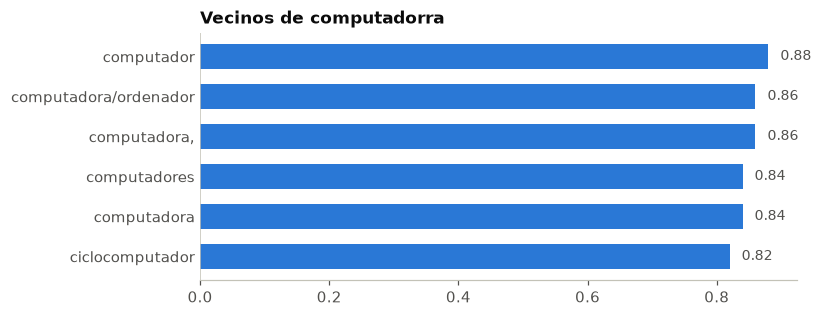

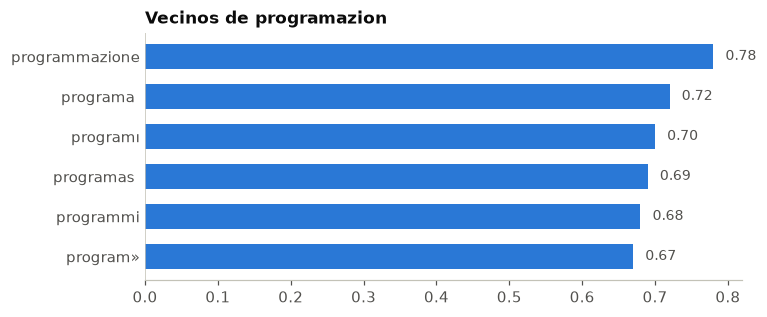

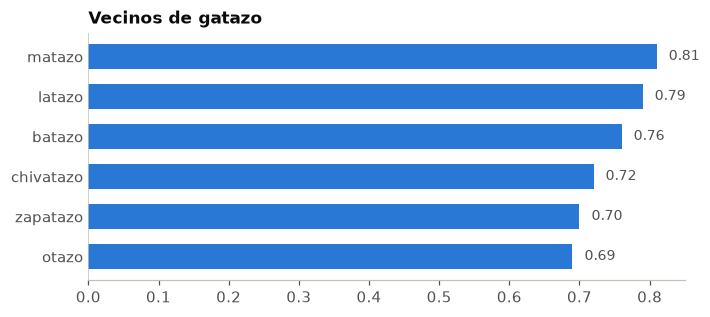

In [10]:
for palabra in ["computadorra", "programazion", "gatazo"]:
    nombres = []
    cosenos = []
    for vecino, coseno in vecinos_de(vectores_fasttext, palabra):
        nombres.append(vecino)
        cosenos.append(coseno)
    utils.dibujar_barras(nombres, cosenos, f"Vecinos de {palabra}")

> **Para mirar.**
>
> - `computadorra` → `computador`, `computadora`…: la forma ayuda (errata cercana).
> - `programazion` → `programmazione`, `programı`, `program»`: formas de otras lenguas y símbolos sueltos.
> - `gatazo` (con entrada) → `matazo`, `latazo`, `batazo`: gana la terminación `-azo`, no el significado.
> - `kjjjj` → `kjj`, `kjw`, `kjd`: no hay significado que recuperar.

Ahora, Word2Vec contra fastText en palabras que **las dos** tienen.

In [11]:
filas = []
for palabra in palabras_con_entrada:
    en_word2vec = []
    for vecino, coseno in vecinos_word2vec[palabra]:
        en_word2vec.append(vecino)
    en_fasttext = []
    for vecino, coseno in vecinos_de(vectores_fasttext, palabra, 5):
        en_fasttext.append(vecino)
    filas.append({
        "palabra": palabra,
        "Word2Vec": ", ".join(en_word2vec),
        "fastText": ", ".join(en_fasttext),
    })
display(pd.DataFrame(filas).set_index("palabra"))

,Word2Vec,fastText
palabra,,
gatito,"cachorro, cachorrito, perrito, conejito, gato","gatitos, gatita, gatitas, patito, ratito"
laburo,"marío, labura, despelote, condenao, dejás","laburar, labur, laburante, saburo, juzaburo"
mate,"mates, hiera, dispare, cace, pegue","jaque, pavić, yerba, mates, draganja"
desayunábamos,"charlábamos, cenábamos, despertábamos, vomitábamos, proseguíamos","dábamos, tomábamos, grabábamos, dejábamos, pasábamos"


> **Para mirar.**
>
> - `laburo`: Word2Vec trae `marío`, `condenao`, `dejás` (casi no lo vio); fastText, `laburar`, `labur`, `laburante` (misma raíz). Acá los n-gramas **suplen la escasez de datos**.
> - `desayunábamos`: Word2Vec trae `cenábamos`, `despertábamos` (acciones de una rutina); fastText, `dábamos`, `tomábamos` (solo la terminación). Acá la forma **le gana al contexto**.
> - `mate`: fastText trae `jaque` y `yerba`, los dos sentidos que tiene en Wikipedia. Word2Vec, formas verbales.

Ninguno de los dos corpus es rioplatense oral: una palabra con entrada no prueba que el modelo represente bien su uso local.

## 5. Decidir cuándo usarlo

| Situación | ¿fastText? |
|---|---|
| Sugerir correcciones de erratas cercanas, agrupar variantes de una misma raíz, no dejar vacío un vector en un sistema exploratorio | Razonable: la forma aporta evidencia |
| Neologismos, vocabulario regional, usos sociales, decisiones sensibles | No alcanza solo: evaluá con datos del dominio y revisá los errores |

| Querés saber… | Mirá… |
|---|---|
| ¿La palabra estuvo en el entrenamiento? | `key_to_index` |
| ¿El modelo puede calcular un vector? | `in` (aviso de cobertura, no de calidad) |
| ¿El vector sirve para tu propósito? | Sus vecinos y una evaluación en tu tarea |

### Microlaboratorio 2 — Informe de cobertura y decisión

**Tarea.** Armar el informe de tres palabras de un contexto donde un sistema toma decisiones (búsqueda educativa, salud, empleo, conversación rioplatense): una errata, una palabra nueva o local y una forma flexionada.  
**Producto.** Un informe de tres palabras, la clasificación de los vecinos de `wasapear` y `covid`, y tu decisión escrita.  
**Antes de empezar.** Secciones 3 y 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `estuvo` | `True` o `False`: ¿la palabra estuvo en el entrenamiento? | el operador `in` aplicado a `vectores_fasttext.key_to_index` (un diccionario) |
| (2) `vecinos` | los 5 vecinos más cercanos | la función `vecinos_de` de la sección 3, con tres argumentos: el modelo, la palabra y `5` |
| Paso 2 `tres_palabras` | tus tres palabras | una lista de 3 textos |
| Paso 3 `clasificacion` | una categoría por vecino | una de estas, **sin tilde**: `semantico` (se relaciona por significado), `morfologico` (comparte raíz o terminación), `grafico` (solo se escribe parecido) o `ruido` |
| Paso 4 `mi_decision` | una o dos oraciones | ¿usarías fastText en ese contexto?, ¿para qué tarea sí y para cuál no?, apoyándote en un vecindario de este cuaderno |

**Comprobación.** cada celda dice `Correcto.` o te da una pista; la clasificación no puede dejar vecinos en `pendiente`.

> **Ayuda 1.** Para la línea (1), mirá cómo armamos la columna `explicito en fastText` en la sección 3.  
> **Ayuda 2.** Para (2), mirá cómo llamamos a `vecinos_de` en la sección 4.

In [12]:
def informe(palabra: str) -> tuple:
    """Arma el informe de cobertura de una palabra en fastText.

    Args:
        palabra: La palabra a consultar.

    Returns:
        Una tupla (estuvo, vecinos): si la palabra estuvo en el
        entrenamiento y sus 5 vecinos mas cercanos.
    """
    estuvo = False  # COMPLETAR (1)
    vecinos = []  # COMPLETAR (2)
    return estuvo, vecinos


estuvo_laburo, vecinos_laburo = informe("laburo")
utils.comprobar(
    estuvo_laburo is True
    and informe("kjjjj")[0] is False
    and len(vecinos_laburo) == 5,
    "revisa (1) y (2): laburo esta en el vocabulario, kjjjj no, y deben "
    "volver 5 vecinos",
)

# PASO 2: cambia estas tres palabras por las tuyas.
tres_palabras = ["turnito", "laburando", "estudiantx"]
for palabra in tres_palabras:
    estuvo, vecinos = informe(palabra)
    print(f"{palabra} | estuvo en el entrenamiento: {estuvo}")
    print("   ", vecinos)

Todavia falta. Pista: revisa (1) y (2): laburo esta en el vocabulario, kjjjj no, y deben volver 5 vecinos
turnito | estuvo en el entrenamiento: False
    []
laburando | estuvo en el entrenamiento: False
    []
estudiantx | estuvo en el entrenamiento: False
    []


In [13]:
CATEGORIAS = ["semantico", "morfologico", "grafico", "ruido", "pendiente"]

# PASO 3: reemplaza cada "pendiente" por una categoria.
clasificacion = {
    "wasapear": {
        "dissapear": "pendiente", "tapear": "pendiente",
        "papear": "pendiente", "remapear": "pendiente",
        "rapear": "pendiente", "capear": "pendiente",
    },
    "covid": {
        "covides": "pendiente", "coview": "pendiente",
        "covida": "pendiente", "covi": "pendiente",
        "dot&pf": "pendiente", "covina": "pendiente",
    },
}

sin_clasificar = 0
for palabra, vecinos in clasificacion.items():
    conteo = {}
    for vecino, categoria in vecinos.items():
        assert categoria in CATEGORIAS, f"'{categoria}' no es valida."
        conteo[categoria] = conteo.get(categoria, 0) + 1
        if categoria == "pendiente":
            sin_clasificar += 1
    print(palabra, "->", conteo)
utils.comprobar(sin_clasificar == 0, f"quedan {sin_clasificar} pendientes")

# PASO 4: escribi tu decision entre las comillas.
mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 8,
    "escribi al menos una oracion completa en mi_decision",
)

wasapear -> {'pendiente': 6}
covid -> {'pendiente': 6}
Todavia falta. Pista: quedan 12 pendientes
Todavia falta. Pista: escribi al menos una oracion completa en mi_decision


## Qué te llevás

- fastText fabrica el vector de una palabra ausente **promediando sus n-gramas**.
- Que haya vector no dice que sirva: `in` mide cobertura, los vecinos ayudan a juzgar la calidad.
- Sirve cuando la forma aporta evidencia (erratas, flexiones); no alcanza para neologismos, variedades locales ni decisiones sensibles.

**Sigue:** cómo se pasa de palabras a textos (cuaderno 04).